# Proyek Machine Learning — Air Quality

**Target prediksi:** `CO(GT)` (regresi)  
**Sumber dataset:** UCI Machine Learning Repository — Air Quality

Notebook ini mencakup tahapan: Data Cleaning, EDA, Data Splitting, Modelling (Linear Regression, Random Forest, Gradient Boosting), evaluasi metrik, dan penyimpanan model terbaik.

## 1. Import library

In [1]:
from pathlib import Path
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme()


## 2. Membaca dataset

In [2]:
CSV_PATH = "AirQualityUCI.csv"
TARGET = "CO(GT)"
OUTPUT_DIR = Path("hasil_air_quality")
OUTPUT_DIR.mkdir(exist_ok=True)

if not Path(CSV_PATH).exists():
    raise FileNotFoundError(
        f"File '{CSV_PATH}' tidak ditemukan. Pastikan file CSV berada di folder yang sama."
    )

# Baca dataset (CSV menggunakan pemisah titik koma dan desimal koma)
df = pd.read_csv(CSV_PATH, sep=";", decimal=",")
df = df.dropna(axis=1, how="all")
df.columns = df.columns.astype(str).str.strip()

display(df.head())
print("Ukuran dataset:", df.shape)
df.info()
display(df.describe(include="all").T)

if TARGET not in df.columns:
    raise ValueError(f"Kolom target '{TARGET}' tidak ditemukan dalam dataset.")


,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
0,10/03/2004,18.00.00,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578
1,10/03/2004,19.00.00,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255
2,10/03/2004,20.00.00,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502
3,10/03/2004,21.00.00,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867
4,10/03/2004,22.00.00,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888


Ukuran dataset: (9471, 15)
<class 'pandas.DataFrame'>
RangeIndex: 9471 entries, 0 to 9470
Data columns (total 15 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Date           9357 non-null   str    
 1   Time           9357 non-null   str    
 2   CO(GT)         9357 non-null   float64
 3   PT08.S1(CO)    9357 non-null   float64
 4   NMHC(GT)       9357 non-null   float64
 5   C6H6(GT)       9357 non-null   float64
 6   PT08.S2(NMHC)  9357 non-null   float64
 7   NOx(GT)        9357 non-null   float64
 8   PT08.S3(NOx)   9357 non-null   float64
 9   NO2(GT)        9357 non-null   float64
 10  PT08.S4(NO2)   9357 non-null   float64
 11  PT08.S5(O3)    9357 non-null   float64
 12  T              9357 non-null   float64
 13  RH             9357 non-null   float64
 14  AH             9357 non-null   float64
dtypes: float64(13), str(2)
memory usage: 1.1 MB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Date,9357,391,11/03/2004,24,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Time,9357,24,18.00.00,390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CO(GT),9357.0,NaN,NaN,NaN,-34.207524,77.65717,-200.0,0.6,1.5,2.6,11.9
PT08.S1(CO),9357.0,NaN,NaN,NaN,1048.990061,329.83271,-200.0,921.0,1053.0,1221.0,2040.0
NMHC(GT),9357.0,NaN,NaN,NaN,-159.090093,139.789093,-200.0,-200.0,-200.0,-200.0,1189.0
C6H6(GT),9357.0,NaN,NaN,NaN,1.865683,41.380206,-200.0,4.0,7.9,13.6,63.7
PT08.S2(NMHC),9357.0,NaN,NaN,NaN,894.595276,342.333252,-200.0,711.0,895.0,1105.0,2214.0
NOx(GT),9357.0,NaN,NaN,NaN,168.616971,257.433866,-200.0,50.0,141.0,284.0,1479.0
PT08.S3(NOx),9357.0,NaN,NaN,NaN,794.990168,321.993552,-200.0,637.0,794.0,960.0,2683.0
NO2(GT),9357.0,NaN,NaN,NaN,58.148873,126.940455,-200.0,53.0,96.0,133.0,340.0


## 3. Data Cleaning

In [3]:
# Cek missing value awal bawaan pandas
display(df.isnull().sum().sort_values(ascending=False).to_frame("missing_awal"))

# Ganti nilai -200 menjadi NaN (penanda missing value dataset UCI)
numeric_columns = df.select_dtypes(include=np.number).columns.tolist()
df[numeric_columns] = df[numeric_columns].replace(-200, np.nan)

# Rekap missing value tiap kolom
missing_report = pd.DataFrame({
    "jumlah_missing": df.isnull().sum(),
    "persentase_missing": (df.isnull().mean() * 100).round(2)
}).sort_values("jumlah_missing", ascending=False)
display(missing_report)
missing_report.to_csv(OUTPUT_DIR / "laporan_missing_value.csv")

# Hapus baris duplikat
print("Jumlah baris duplikat:", int(df.duplicated().sum()))
df = df.drop_duplicates().copy()
print("Ukuran data setelah drop duplikat:", df.shape)


,missing_awal
Date,114
Time,114
CO(GT),114
PT08.S1(CO),114
NMHC(GT),114
C6H6(GT),114
PT08.S2(NMHC),114
NOx(GT),114
PT08.S3(NOx),114
NO2(GT),114


,jumlah_missing,persentase_missing
NMHC(GT),8557,90.35
CO(GT),1797,18.97
NO2(GT),1756,18.54
NOx(GT),1753,18.51
PT08.S2(NMHC),480,5.07
C6H6(GT),480,5.07
PT08.S1(CO),480,5.07
PT08.S5(O3),480,5.07
T,480,5.07
PT08.S3(NOx),480,5.07


Jumlah baris duplikat: 113
Ukuran data setelah drop duplikat: (9358, 15)


## 4. Menyiapkan fitur waktu dan target

In [4]:
# Ekstrak fitur tanggal dan jam jika tersedia
if "Date" in df.columns:
    date_only = pd.to_datetime(df["Date"], dayfirst=True, errors="coerce")
    df["Month"] = date_only.dt.month
    df["Day"] = date_only.dt.day
    df["DayOfWeek"] = date_only.dt.dayofweek
else:
    date_only = pd.Series(pd.NaT, index=df.index)

if "Time" in df.columns:
    time_text = (
        df["Time"].astype(str).str.strip()
        .str.replace(".", ":", regex=False)
    )
    parsed_time = pd.to_datetime(time_text, format="%H:%M:%S", errors="coerce")
    df["Hour"] = parsed_time.dt.hour
else:
    parsed_time = pd.Series(pd.NaT, index=df.index)

if "Date" in df.columns:
    df["_DateTime"] = date_only + pd.to_timedelta(
        parsed_time.dt.hour.fillna(0), unit="h"
    )

# Drop missing value pada kolom target (CO)
target_missing = int(df[TARGET].isna().sum())
print("Missing target:", target_missing)
df = df.dropna(subset=[TARGET]).copy()

# Cek jumlah baris data setelah cleaning
print("Dimensi data baru:", df.shape)
if len(df) >= 1000:
    print(f"Total baris: {len(df):,} (lolos syarat tugas > 1.000)")

df.to_csv(OUTPUT_DIR / "air_quality_cleaned.csv", index=False)


Missing target: 1684
Dimensi data baru: (7674, 20)
Total baris: 7,674 (lolos syarat tugas > 1.000)


## 5. Pemeriksaan outlier dengan IQR

In [5]:
# Hitung batas outlier IQR (hanya evaluasi data, tidak di-drop)
numeric_for_outlier = df.select_dtypes(include=np.number).drop(
    columns=["_DateTime"], errors="ignore"
)
outlier_rows = []

for col in numeric_for_outlier.columns:
    values = numeric_for_outlier[col].dropna()
    if values.empty:
        continue
    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = int(((values < lower) | (values > upper)).sum())
    outlier_rows.append({
        "kolom": col,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "batas_bawah": lower,
        "batas_atas": upper,
        "jumlah_outlier": count
    })

outlier_report = pd.DataFrame(outlier_rows)
display(outlier_report)
outlier_report.to_csv(OUTPUT_DIR / "laporan_outlier_iqr.csv", index=False)


,kolom,Q1,Q3,IQR,batas_bawah,batas_atas,jumlah_outlier
0,CO(GT),1.1000,2.9000,1.8000,-1.60000,5.60000,215
1,PT08.S1(CO),946.0000,1246.0000,300.0000,496.00000,1696.00000,90
2,NMHC(GT),71.0000,301.0000,230.0000,-274.00000,646.00000,54
3,C6H6(GT),4.6000,14.3000,9.7000,-9.95000,28.85000,177
4,PT08.S2(NMHC),743.0000,1125.2500,382.2500,169.62500,1698.62500,47
5,NOx(GT),103.0000,339.0000,236.0000,-251.00000,693.00000,383
6,PT08.S3(NOx),649.0000,960.0000,311.0000,182.50000,1426.50000,191
7,NO2(GT),80.0000,144.0000,64.0000,-16.00000,240.00000,96
8,PT08.S4(NO2),1203.0000,1673.0000,470.0000,498.00000,2378.00000,65
9,PT08.S5(O3),744.7500,1305.0000,560.2500,-95.62500,2145.37500,65


### Boxplot target CO(GT)

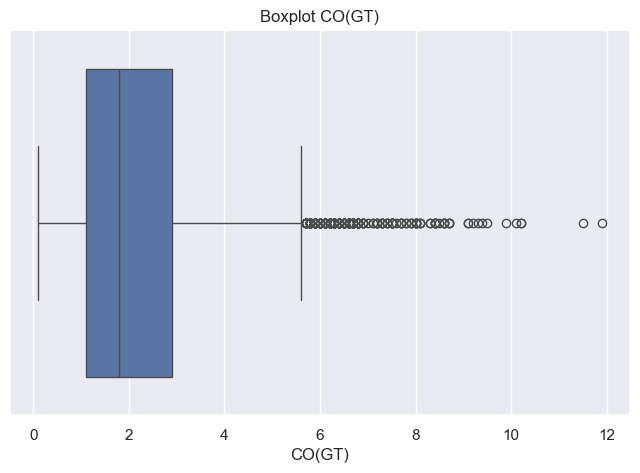

In [6]:
# Boxplot target CO(GT)
plt.figure(figsize=(8, 5))
sns.boxplot(x=df[TARGET])
plt.title(f"Boxplot {TARGET}")
plt.xlabel(TARGET)
plt.show()


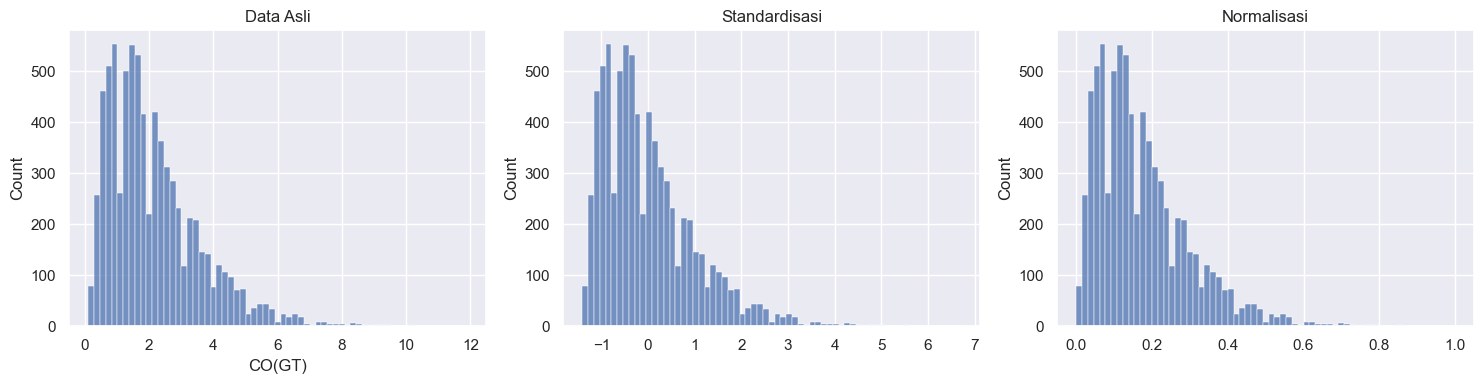

In [7]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler
import matplotlib.pyplot as plt
import seaborn as sns

# Contoh perbandingan transformasi pada target CO(GT)
kolom = "CO(GT)"

data_asli = df[[kolom]].dropna()

# Standardisasi (StandardScaler)
scaler_std = StandardScaler()
data_std = scaler_std.fit_transform(data_asli)

# Normalisasi rentang 0-1 (MinMaxScaler)
scaler_minmax = MinMaxScaler()
data_norm = scaler_minmax.fit_transform(data_asli)

# Plot distribusi
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.histplot(data_asli[kolom], ax=axes[0])
axes[0].set_title("Data Asli")

sns.histplot(data_std.flatten(), ax=axes[1])
axes[1].set_title("Standardisasi")

sns.histplot(data_norm.flatten(), ax=axes[2])
axes[2].set_title("Normalisasi")

plt.tight_layout()
plt.show()


## 6. EDA — distribusi target

count    7674.000000
mean        2.152750
std         1.453252
min         0.100000
25%         1.100000
50%         1.800000
75%         2.900000
max        11.900000
Name: CO(GT), dtype: float64

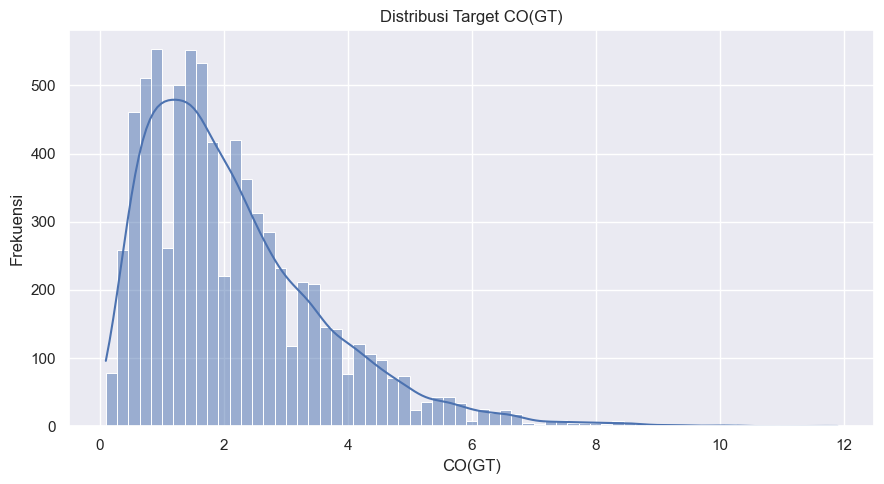

In [8]:
display(df[TARGET].describe())

plt.figure(figsize=(9, 5))
sns.histplot(df[TARGET], kde=True)
plt.title(f"Distribusi Target {TARGET}")
plt.xlabel(TARGET)
plt.ylabel("Frekuensi")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "01_distribusi_target.png", dpi=150)
plt.show()


## 7. EDA — histogram fitur numerik

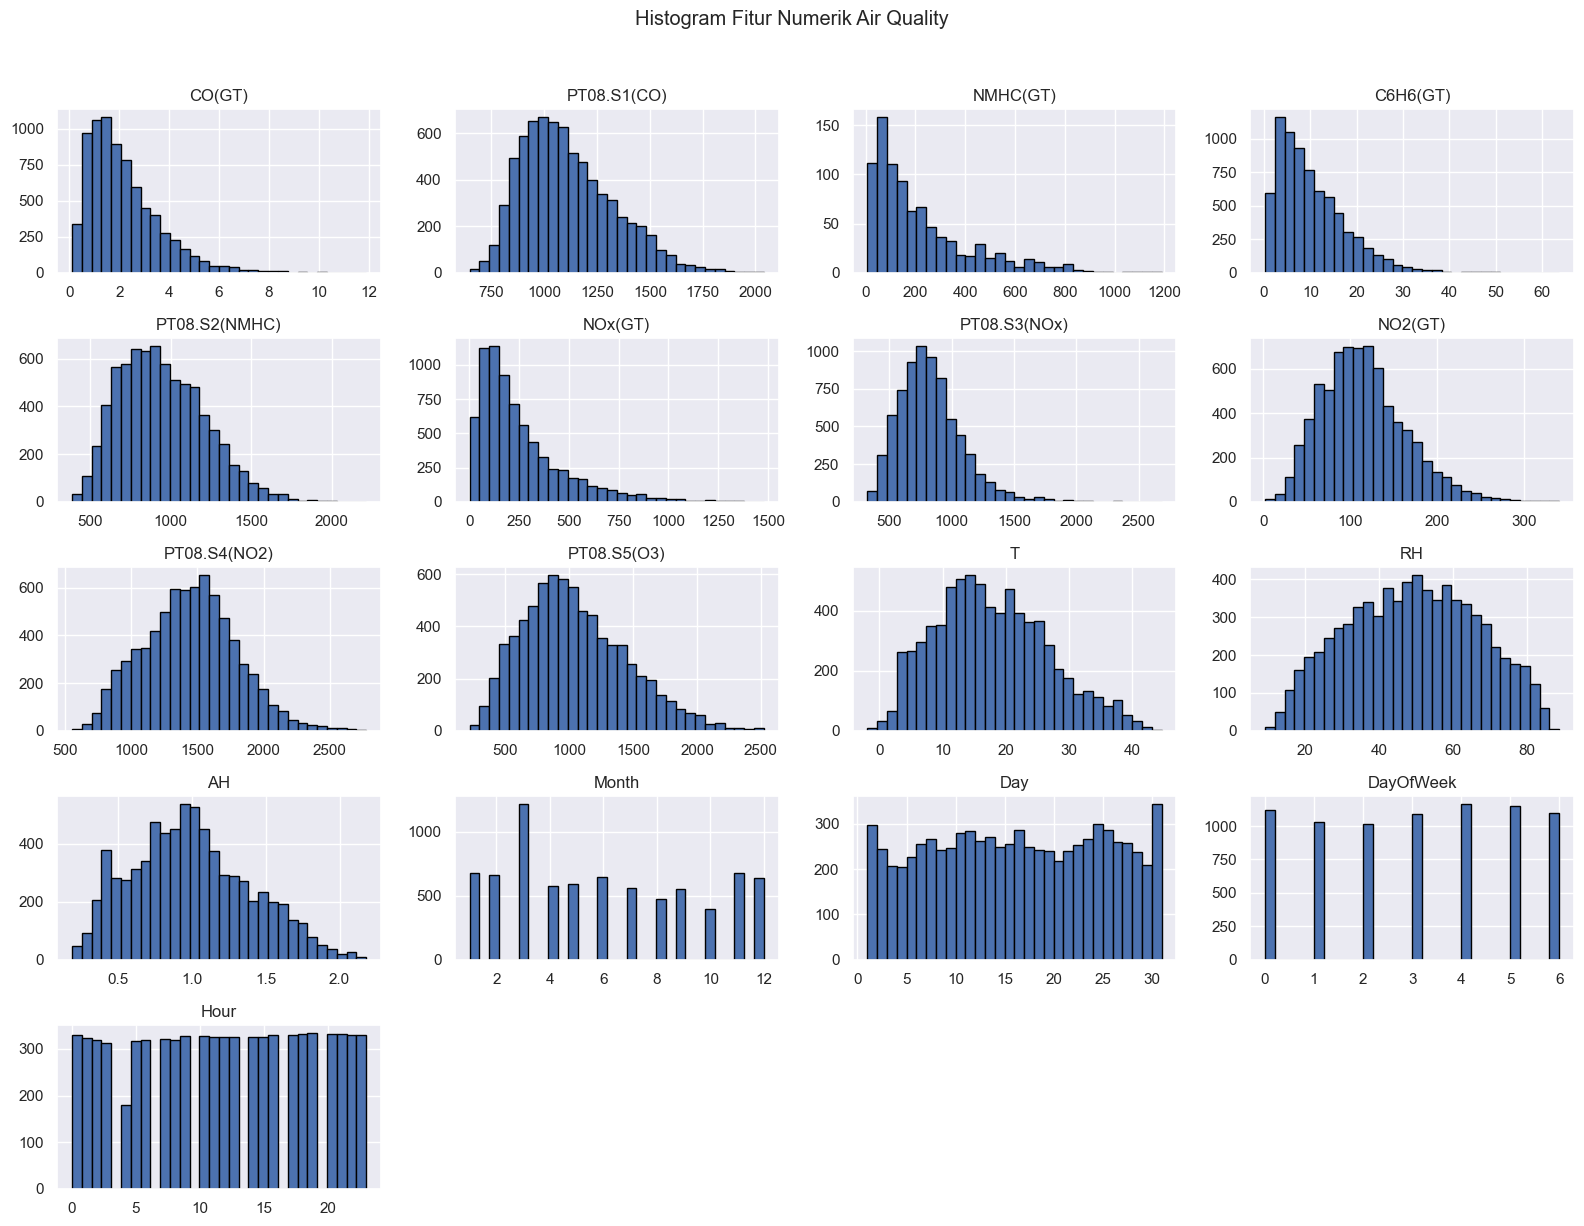

In [9]:
eda_numeric = df.select_dtypes(include=np.number).drop(
    columns=["_DateTime"], errors="ignore"
)
eda_numeric = eda_numeric.loc[:, eda_numeric.notna().any()]

eda_numeric.hist(figsize=(16, 12), bins=30, edgecolor="black")
plt.suptitle("Histogram Fitur Numerik Air Quality", y=1.02)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "02_histogram_fitur.png", dpi=150, bbox_inches="tight")
plt.show()


## 8. EDA — korelasi

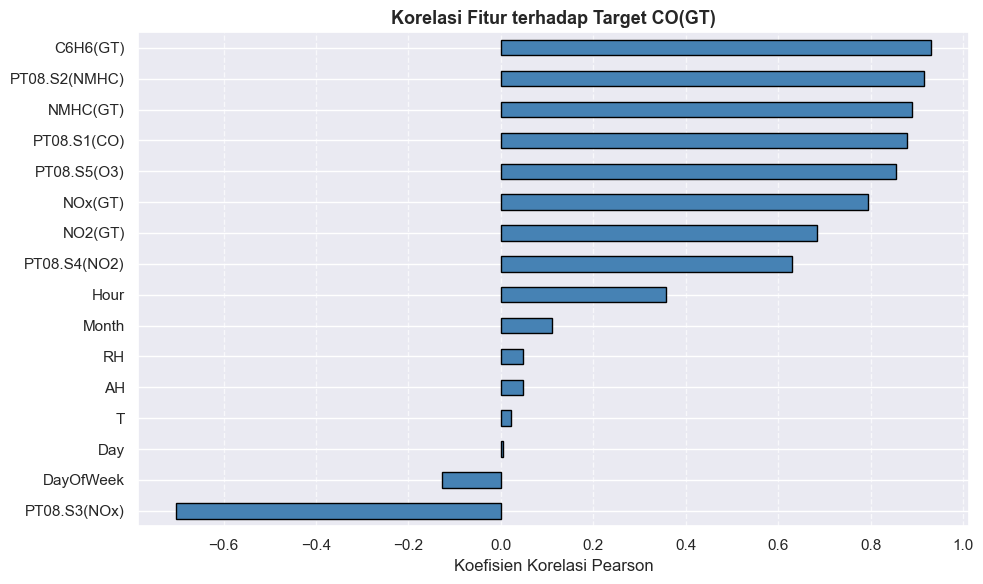

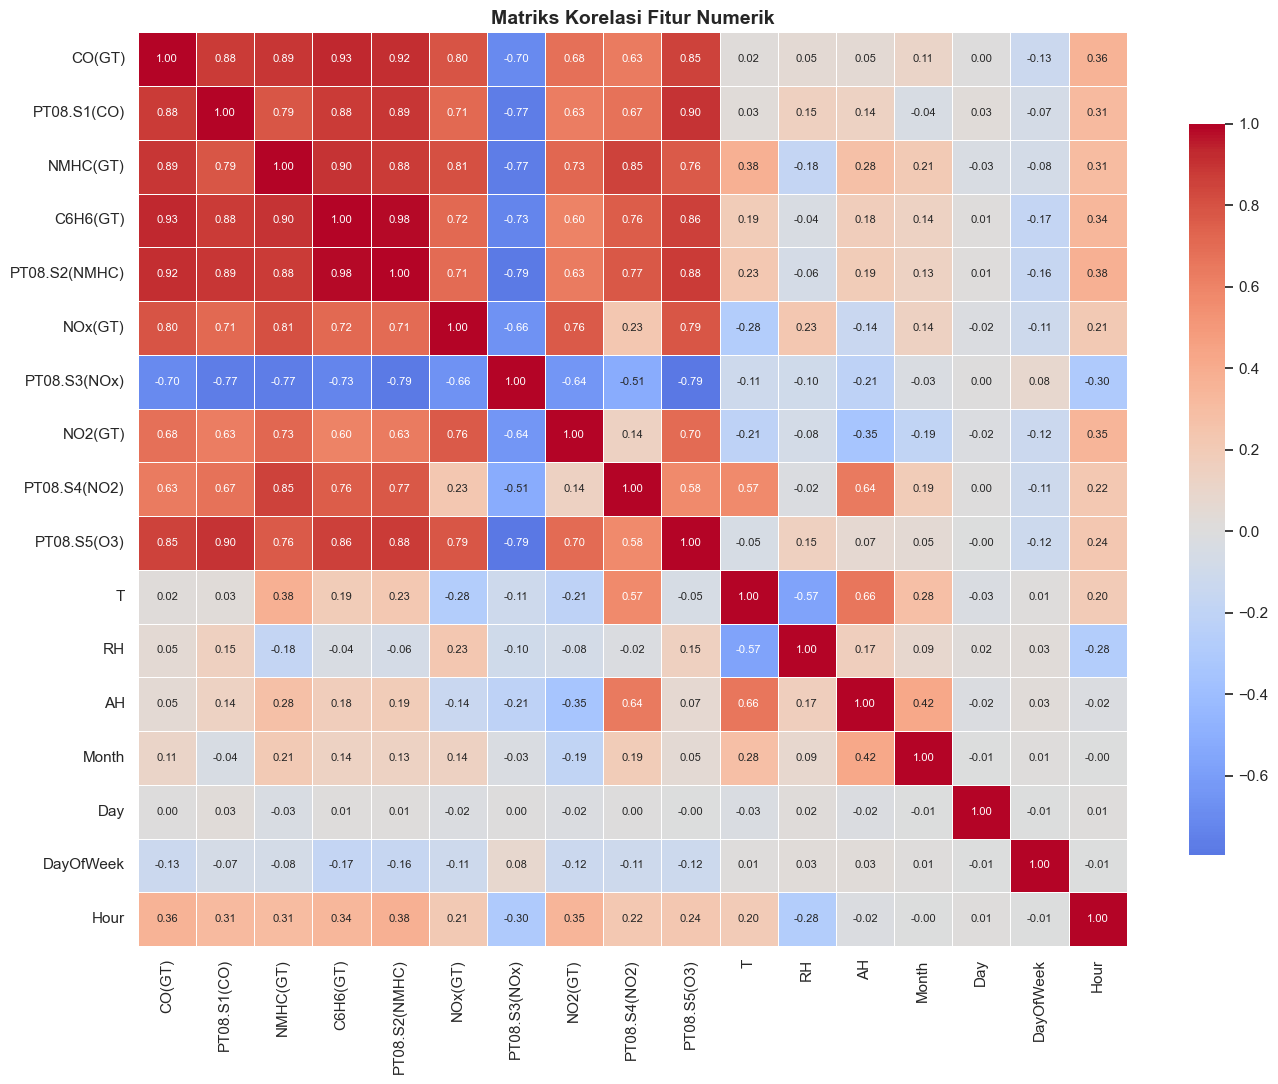

In [10]:
corr_data = eda_numeric.corr(numeric_only=True)

if TARGET in corr_data.columns:
    target_corr = corr_data[TARGET].drop(TARGET).sort_values(ascending=True)
    
    # 1. Grafik Batang Horizontal Korelasi Target 
    plt.figure(figsize=(10, 6))
    target_corr.plot(kind="barh", color="steelblue", edgecolor="black")
    plt.title("Korelasi Fitur terhadap Target CO(GT)", fontsize=13, fontweight="bold")
    plt.xlabel("Koefisien Korelasi Pearson")
    plt.grid(axis="x", linestyle="--", alpha=0.7)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "03_korelasi_barh.png", dpi=300)
    plt.show()

# 2. Heatmap dengan Angka di Dalam Kotak (annot=True)
plt.figure(figsize=(14, 11))
sns.heatmap(
    corr_data, 
    cmap="coolwarm", 
    center=0, 
    annot=True,          # Munculkan angka di setiap kotak!
    fmt=".2f",           # Bulatkan 2 angka di belakang koma
    annot_kws={"size": 8}, # Ukuran font pas biar tidak bertumpuk
    linewidths=0.5,      # Garis pemisah antar kotak biar tajam
    cbar_kws={"shrink": 0.8}
)
plt.title("Matriks Korelasi Fitur Numerik", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "03_matriks_korelasi.png", dpi=300) 
plt.show()

## 9. Menyiapkan X dan y

In [11]:
# Pisahkan fitur (X) dan target (y), kolom waktu teks tidak dipakai langsung
exclude_columns = {TARGET, "Date", "Time", "_DateTime"}
feature_columns = [
    col for col in df.columns
    if col not in exclude_columns and pd.api.types.is_numeric_dtype(df[col])
]
feature_columns = [col for col in feature_columns if df[col].notna().any()]

X = df[feature_columns].copy()
y = df[TARGET].copy()

print("Target (y):", TARGET)
print("Fitur (X):", feature_columns)
print("Jumlah fitur:", len(feature_columns))
print("Jumlah baris:", len(X))


Target (y): CO(GT)
Fitur (X): ['PT08.S1(CO)', 'NMHC(GT)', 'C6H6(GT)', 'PT08.S2(NMHC)', 'NOx(GT)', 'PT08.S3(NOx)', 'NO2(GT)', 'PT08.S4(NO2)', 'PT08.S5(O3)', 'T', 'RH', 'AH', 'Month', 'Day', 'DayOfWeek', 'Hour']
Jumlah fitur: 16
Jumlah baris: 7674


## 10. Data Splitting

In [12]:
# Urutkan data berdasarkan waktu sebelum split
if "_DateTime" in df.columns and df["_DateTime"].notna().any():
    order = df["_DateTime"].sort_values(kind="stable").index
    X = X.loc[order]
    y = y.loc[order]

# Split 80% train dan 20% test secara kronologis
split_index = int(len(X) * 0.8)
if split_index <= 0 or split_index >= len(X):
    raise ValueError("Jumlah data tidak cukup untuk split.")

x_train = X.iloc[:split_index].copy()
x_test = X.iloc[split_index:].copy()
y_train = y.iloc[:split_index].copy()
y_test = y.iloc[split_index:].copy()

print("Total data :", len(X))
print("Data train :", len(x_train))
print("Data test  :", len(x_test))


Total data : 7674
Data train : 6139
Data test  : 1535


## 11. Modelling

In [13]:
# Definisi pipeline model (imputer median dan scaler di-fit hanya pada train)
models = {
    "Linear Regression": Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]),
    "Random Forest": Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestRegressor(
            n_estimators=150, random_state=42, n_jobs=-1
        ))
    ]),
    "Gradient Boosting": Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("model", GradientBoostingRegressor(random_state=42))
    ])
}

results = []
fitted_models = {}

for model_name, model in models.items():
    print("Melatih model:", model_name)
    model.fit(x_train, y_train)
    predictions = model.predict(x_test)

    mae = mean_absolute_error(y_test, predictions)
    mse = mean_squared_error(y_test, predictions)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": model_name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2
    })
    fitted_models[model_name] = model

results_df = pd.DataFrame(results).sort_values(
    by=["R2", "MAE"], ascending=[False, True]
).reset_index(drop=True)

display(results_df.round(4))
results_df.to_csv(OUTPUT_DIR / "perbandingan_model.csv", index=False)


Melatih model: Linear Regression
Melatih model: Random Forest
Melatih model: Gradient Boosting


,Model,MAE,MSE,RMSE,R2
0,Linear Regression,0.3442,0.2714,0.5209,0.8499
1,Random Forest,0.3630,0.2916,0.5400,0.8387
2,Gradient Boosting,0.3868,0.3280,0.5727,0.8185


## 12. Grafik perbandingan model

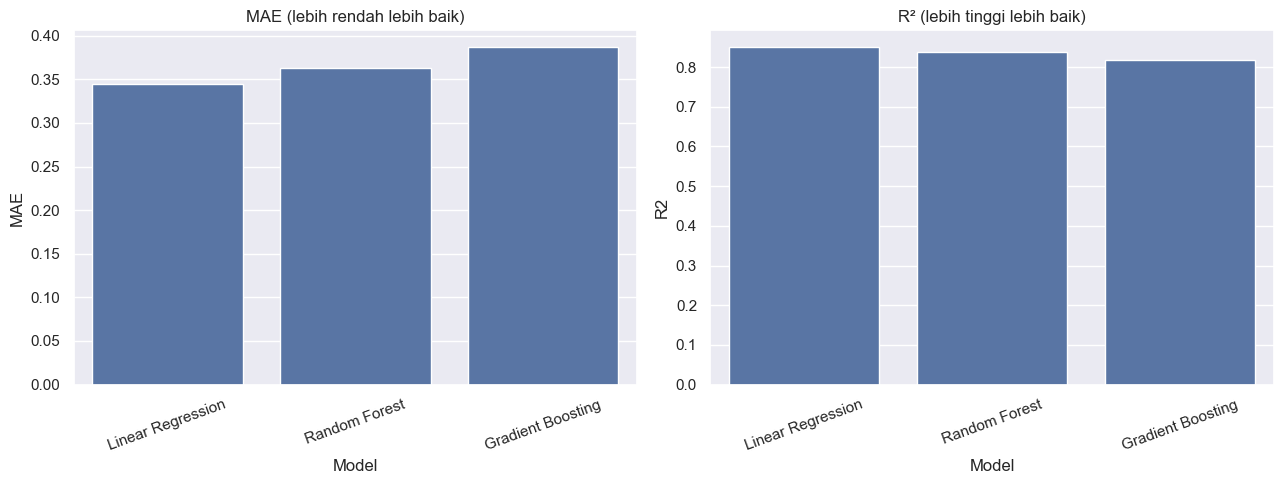

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.barplot(data=results_df, x="Model", y="MAE", ax=axes[0])
axes[0].set_title("MAE (lebih rendah lebih baik)")
axes[0].tick_params(axis="x", rotation=20)

sns.barplot(data=results_df, x="Model", y="R2", ax=axes[1])
axes[1].set_title("R² (lebih tinggi lebih baik)")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "04_perbandingan_model.png", dpi=150)
plt.show()


## 13. Simpan model terbaik dan hasil prediksi

In [15]:
# Simpan model terbaik ke file joblib
best_model_name = results_df.iloc[0]["Model"]
best_model = fitted_models[best_model_name]

model_path = OUTPUT_DIR / "model_air_quality_terbaik.joblib"
joblib.dump({
    "model": best_model,
    "target": TARGET,
    "features": feature_columns,
    "model_name": best_model_name
}, model_path)

# Simpan hasil prediksi test ke CSV
best_predictions = best_model.predict(x_test)
prediction_results = pd.DataFrame({
    "nilai_aktual": y_test.to_numpy(),
    "nilai_prediksi": best_predictions
})
prediction_results.to_csv(OUTPUT_DIR / "hasil_prediksi_test.csv", index=False)

print("Model terbaik (urutan R² lalu MAE):", best_model_name)
print("Model tersimpan di:", model_path)
print("Semua hasil tersimpan di:", OUTPUT_DIR.resolve())
display(prediction_results.head(10))


Model terbaik (urutan R² lalu MAE): Linear Regression
Model tersimpan di: hasil_air_quality\model_air_quality_terbaik.joblib
Semua hasil tersimpan di: D:\Jupyter\Air-Quality-Prediction\hasil_air_quality


,nilai_aktual,nilai_prediksi
0,0.5,0.217754
1,0.8,0.567992
2,1.1,0.780986
3,1.1,0.707140
4,1.1,0.749608
5,1.1,0.730402
6,1.1,0.747354
7,1.2,0.854181
8,1.0,0.673614
9,1.2,0.705250


## 14. Ringkasan Metrik Evaluasi

- **MAE:** Rata-rata selisih absolut antara nilai prediksi dan aktual (makin kecil makin baik).
- **MSE:** Rata-rata kuadrat kesalahan prediksi (makin kecil makin baik).
- **RMSE:** Akar kuadrat dari MSE, satuannya sama dengan nilai target mg/m³ (makin kecil makin baik).
- **R²:** Koefisien determinasi yang menggambarkan variasi target yang berhasil dijelaskan oleh model (makin mendekati 1 makin baik).

## Kesimpulan Proyek

1. **Model Terbaik**:
   Berdasarkan hasil pengujian pada data uji (testing set) 20% bagian akhir secara kronologis, **Linear Regression** mencatatkan performa terbaik di antara ketiga algoritma yang diuji:
   - **MAE** : 0.3442 (paling rendah)
   - **MSE** : 0.2714 (paling rendah)
   - **RMSE**: 0.5209 (paling rendah)
   - **R²**  : 0.8499 (paling tinggi)

2. **Perbandingan Performa**:
   - Peringkat 1: **Linear Regression** (R² = 0.8499, MAE = 0.3442)
   - Peringkat 2: **Random Forest Regressor** (R² = 0.8397, MAE = 0.3630)
   - Peringkat 3: **Gradient Boosting Regressor** (R² = 0.8185, MAE = 0.3968)

3. **Interpretasi R²**:
   Nilai R² sebesar **0.8499** pada Linear Regression menunjukkan bahwa model mampu menjelaskan sekitar **84.99% variasi konsentrasi CO** pada data evaluasi menggunakan fitur sensor dan kondisi cuaca yang tersedia.

4. **Integritas Metodologi & Pencegahan Data Leakage**:
   - Pembagian data dilakukan secara kronologis (80% awal untuk training, 20% akhir untuk testing).
   - Pengisian nilai hilang (*SimpleImputer*) dan standardisasi (*StandardScaler*) diisolasi ke dalam `Pipeline`, sehingga informasi dari data testing tidak bocor ke tahap pelatihan.